In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")



Libraries imported successfully!


In [2]:
train = pd.read_csv("../data/train.csv")

print("Training dataset loaded successfully!")
print(train.shape)

Training dataset loaded successfully!
(1460, 81)


In [3]:
print("First 5 rows:")
display(train.head())

First 5 rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
print("Number of rows:", train.shape[0])
print("Number of columns:", train.shape[1])

print("\nColumn names:")
print(train.columns.tolist())

Number of rows: 1460
Number of columns: 81

Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'Enclos

In [5]:
missing_values = train.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

Columns with missing values:
LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


In [6]:
print("SalePrice Statistics:")
print(train["SalePrice"].describe())

SalePrice Statistics:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


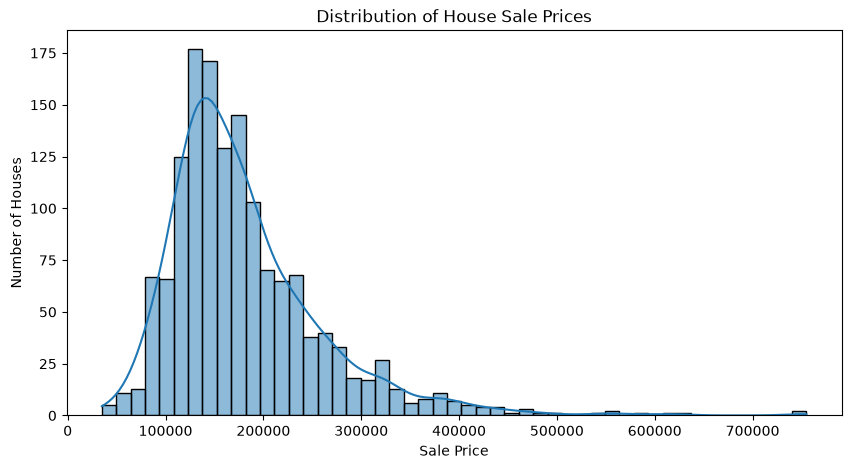

In [7]:
# Check the distribution of house prices

plt.figure(figsize=(10, 5))
sns.histplot(train["SalePrice"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.show()

In [8]:
# Handle missing values

# Columns where missing means the feature is not present
none_columns = [
    "PoolQC", "MiscFeature", "Alley", "Fence",
    "FireplaceQu", "GarageType", "GarageFinish",
    "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "MasVnrType"
]

for col in none_columns:
    train[col] = train[col].fillna("None")

# Numerical columns where missing values can be replaced with the median
median_columns = [
    "LotFrontage", "MasVnrArea", "GarageYrBlt"
]

for col in median_columns:
    train[col] = train[col].fillna(train[col].median())

# Electrical has only one missing value, so use the most common value
train["Electrical"] = train["Electrical"].fillna(train["Electrical"].mode()[0])

print("Missing values handled successfully!")
print("Total remaining missing values:", train.isnull().sum().sum())

Missing values handled successfully!
Total remaining missing values: 0


In [9]:
# Separate features (X) and target (y)

X = train.drop("SalePrice", axis=1)
y = train["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 80)
Target shape: (1460,)


In [10]:
# Identify categorical and numerical columns

categorical_columns = X.select_dtypes(include=["object"]).columns
numerical_columns = X.select_dtypes(exclude=["object"]).columns

print("Number of categorical columns:", len(categorical_columns))
print("Number of numerical columns:", len(numerical_columns))

Number of categorical columns: 43
Number of numerical columns: 37


C:\Users\user\AppData\Local\Temp\ipykernel_19452\4092841521.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object"]).columns


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Preprocessing for numerical columns
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# Split data into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_valid shape:", X_valid.shape)
print("y_train shape:", y_train.shape)
print("y_valid shape:", y_valid.shape)

X_train shape: (1168, 80)
X_valid shape: (292, 80)
y_train shape: (1168,)
y_valid shape: (292,)


In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Create the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

# Make predictions on validation data
y_pred = model.predict(X_valid)

# Evaluate the model
rmse = mean_squared_error(y_valid, y_pred) ** 0.5
mae = mean_absolute_error(y_valid, y_pred)
r2 = r2_score(y_valid, y_pred)

print("Model Performance")
print("-----------------")
print("RMSE:", rmse)
print("MAE:", mae)
print("R² Score:", r2)

Model Performance
-----------------
RMSE: 28943.55701208197
MAE: 17547.46625570776
R² Score: 0.8907830684271703


In [13]:
# Load the test dataset
test = pd.read_csv("../data/test.csv")

# Keep the same features used for training
X_test = test[X.columns]

# Generate predictions
test_predictions = model.predict(X_test)

# Create submission file
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

# Save submission file
submission.to_csv("../outputs/submission.csv", index=False)

print("Submission file created successfully!")
print("Shape:", submission.shape)
print(submission.head())

Submission file created successfully!
Shape: (1459, 2)
     Id      SalePrice
0  1461  129288.360000
1  1462  152877.666667
2  1463  177518.073333
3  1464  187059.496667
4  1465  203225.083333
